# 17 Von der Anomalie zur Handlungsempfehlung

Teil 5: Anomalien und Monitoring

**Worum es geht**
- Ausgangspunkt Notebook 16: netzweites und stationseigenes Erwartungswertmodell bestehen die Begehungsvalidierung und messen Verschiedenes (Spearman 0,14).
- Problem: 55 von 100 Stationen haben dort kein eindeutiges Muster. Ohne Muster gibt es keine Empfehlung.
- Ziel: je auffälliger Station ein Muster, eine Maßnahme, ein nachvollziehbarer Schweregrad und eine priorisierte Liste ohne Adressen.

**Daten**
- liest: Stundenreihen in `data/processed/real_meters`, Außentemperatur aus dem DWD-Cache, Begehungstabelle, `data/processed/wintervergleich_kernwinter.csv`, Prioritätsscores aus `src/priority.py`
- schreibt: `data/processed/empfehlungsliste.csv`, `data/processed/empfehlung_kontext.json`
- vorher ausführen: Notebook 00, Notebook 04 (für `wintervergleich_kernwinter.csv`)

**Code**
- Logik in `src/empfehlung.py` und `src/freitext.py`, Tests in `tests/test_empfehlung.py` und `tests/test_freitext.py`

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import anomalie as an
from src import clustervalidierung as cvl
from src import empfehlung as em
from src import freitext as ft
from src import load_begehungen as lb
from src import nb00_daten as nb00
from src import priority as pr
from src import tagespanel as tp
from src import weather

from sklearn.preprocessing import StandardScaler

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)

METER_DIR = ROOT / "data" / "processed" / "real_meters"
SPALTEN = {
    "Energy (kWh)": "energy", "Volume flow (l/h)": "flow",
    "Power (kW)": "power", "Temperature difference (°C)": "dt",
    "Flow temperature (°C)": "vl", "Return temperature (°C)": "rt",
    "Volume (m³)": "volume",
}
t0 = time.time()


def tick(txt):
    print(f"[{time.time() - t0:6.0f}s] {txt}")

## 1 Rechenbasis

- Stundenreihen aus Notebook 00 über `nb00.lade_serien(METER_DIR, leere_stunden_entfernen=False)`: 100 Zähler bis 11.07.2025, fünf davon mit Nachlieferung bis 20.07.2026.
- Das Tagespanel wird mit denselben Aufrufen wie in Notebook 16 neu gerechnet (Seed 42).

In [2]:
#Panelbau
#Raster aus NB 00 unverändert, nur leere Zählerstände ergänzt
serien = nb00.lade_serien(METER_DIR, leere_stunden_entfernen=False)
von = min(d.index[0] for d in serien.values() if len(d))
bis = max(d.index[-1] for d in serien.values() if len(d))
t_out = weather.load_outdoor_temperature(von, bis, allow_download=False)
tick(f"{len(serien)} Zaehlerreihen, {von:%Y-%m-%d} bis {bis:%Y-%m-%d}")

panel_h, ausschluss = cvl.lade_stundenpanel(METER_DIR)
panel_h = cvl.mit_kontext(panel_h, t_out)
X = StandardScaler().fit_transform(panel_h[cvl.BETRIEBS_FEATURES])
panel_h["cluster"] = cvl.fit_minibatch_kmeans(X, 5, n_init=10)
profil_h = cvl.zentroid_profil(panel_h[cvl.BETRIEBS_FEATURES].to_numpy(),
                               panel_h["cluster"].to_numpy(),
                               cvl.BETRIEBS_FEATURES)
kandidat = profil_h[profil_h["flow_norm"] > 0.3]
KURZ = int(kandidat["dt"].idxmin())
ANTEIL = f"anteil_c{KURZ}"
tick(f"Stundencluster, Kurzschlussverdacht ist Cluster {KURZ}")

panel = tp.baue_tagespanel(serien, stundencluster=panel_h, t_out=t_out)
panel, info_netz = an.erwartungsmodell_netz(panel)
panel, bilanz_station = an.erwartungsmodell_station(panel)
DETEKTOREN = [f"score_{an.D_RESID_NETZ}", f"score_{an.D_RESID_STATION}"]
schwellen = {}
for d in DETEKTOREN:
    panel, s = an.persistente_tage(panel, d)
    schwellen[d] = s
panel.attrs["kurzschlusscluster"] = KURZ
tick(f"Tagespanel {panel.shape}, {panel['meter'].nunique()} Zaehler, "
     f"r2 netzweit {info_netz['r2']:.3f}")
print("Tagesschwellen:", {k.replace('score_', ''): round(v, 2)
                          for k, v in schwellen.items()})

[     1s] 93 Zaehlerreihen, 2021-11-01 bis 2026-07-20


[     2s] Stundencluster, Kurzschlussverdacht ist Cluster 1


[    50s] Tagespanel (88792, 51), 93 Zaehler, r2 netzweit 0.035
Tagesschwellen: {'residuum_netz': 22.14, 'residuum_station': 7.92}


## 2 Warum so viele Stationen ohne Muster blieben

- Alte Zuordnung aus Notebook 16: Quantilsregeln über alle Stationen. Ein Muster greift nur, wenn alle seine Bedingungen zugleich erfüllt sind.
- Unten gegen die persistente Auffälligkeit gekreuzt.

In [3]:
MUSTERSPALTEN = ["rt_vl_kopplung", "dt_mean_loaded", "rt_traege_anteil",
                 "rt_d1_abs_mean", "rt_d2_abs_mean", "flow_median",
                 "last_anteil", "score_residuum_netz"]
profil_alt = an.stationsprofil(panel, MUSTERSPALTEN)
muster_alt = an.muster_je_station(profil_alt)
print("Alte Musterzuordnung ueber alle Stationen")
print(muster_alt["muster"].value_counts().to_string())

kenn_roh = em.kennzahlen(panel, ANTEIL)
auff_tab = pd.DataFrame({
    "meter": kenn_roh["meter"].astype(int),
    "auffaellig": em.auffaellige_stationen(kenn_roh).to_numpy()})
kreuz = muster_alt.merge(auff_tab, on="meter", how="left")
print()
print("Muster gegen persistente Auffaelligkeit")
print(pd.crosstab(kreuz["muster"], kreuz["auffaellig"]).to_string())

Alte Musterzuordnung ueber alle Stationen
muster
kein eindeutiges Muster                                                50
unruhige Regelung                                                      16
Ruecklauf ueber Erwartung ohne weiteres Merkmal                        12
Ruecklauf reagiert kaum, Verdacht festsitzendes oder offenes Ventil     7
Ruecklauf folgt dem Vorlauf, Verdacht hydraulischer Kurzschluss         5
Durchfluss ohne nennenswerte Abnahme                                    3

Muster gegen persistente Auffaelligkeit
auffaellig                                                           False  True 
muster                                                                           
Durchfluss ohne nennenswerte Abnahme                                     1      2
Ruecklauf folgt dem Vorlauf, Verdacht hydraulischer Kurzschluss          3      2
Ruecklauf reagiert kaum, Verdacht festsitzendes oder offenes Ventil      6      1
Ruecklauf ueber Erwartung ohne weiteres Merkmal         

- 40 der 50 Stationen ohne Muster sind nicht persistent auffällig. Dort ist „kein Muster“ richtig.
- Von 26 persistent auffälligen Stationen bleiben 19 ohne verwertbare Diagnose (10 ohne Muster, 9 mit Auffangmuster).
- Zweite Ursache: ein oberes Quintil trifft rund 19 von 93 Stationen, zwei unabhängige Bedingungen zusammen im Mittel knapp 4.
- Folgerung: Muster nur noch auf auffälligen Stationen zuordnen, mit gewichteter Evidenz statt starrer Und-Verknüpfung.

## 3 Neuer Musterkatalog

- Auffällig heißt: nach einem der beiden Detektoren an mehr als 10 % der Tage persistent auffällig.
- Evidenz eines Musters = gewichtetes Mittel der rangbasierten z-Werte seiner Indikatoren. Es gewinnt das Muster mit der höchsten Evidenz, sofern sie mindestens 0,6 beträgt.
- Rang statt Median und MAD, weil sonst z. B. der Volumenstrom (Median 38 l/h, Maximum rund 14.500 l/h) extreme z-Werte liefert.
- Sieben Muster. Die zwei allgemeinen greifen nur, wenn kein spezifisches reicht.

In [4]:
kenn = em.kennzahlen(panel, ANTEIL)
eff = em.effizienz(panel, kenn)
print(f"Kennzahlenprofil {kenn.shape}")
print(kenn.describe().round(2).to_string())

Kennzahlenprofil (93, 24)
             meter     rt     dt   last     flow   kopp     d1     d2  traege   reak   perf  spanne   power   n_tage  score_netz  pers_netz  score_station  pers_station  rt_winter  dt_winter  rt_sommer  last_sommer  rt_delta_saison  anteil_kurzschluss
count        93.00  93.00  92.00  93.00    93.00  93.00  93.00  93.00   93.00  93.00  93.00   93.00   93.00    93.00       93.00      93.00           93.0         93.00      93.00      92.00      93.00        93.00            93.00               92.00
mean   74378988.27  45.88  23.67   0.45   368.13   0.59   4.86   7.97    0.01   0.65  24.97   23.82    6.07   952.75       -0.52       0.09           -0.0          0.06      46.36      25.66      46.13         0.16            -0.23                0.12
std     6710551.10  12.18   7.76   0.34  1370.74   0.23   2.74   4.77    0.03   0.55  10.20    8.99   27.35   394.05       10.68       0.21            0.0          0.10      11.47       8.19      14.89         0.20    

In [5]:
bilanz = em.musterbilanz(kenn)
print("Musterzuordnung, neu")
print(bilanz.to_string(index=False))

n_auff = int(bilanz.loc[bilanz["auffaellig"], "n_stationen"].sum())
ohne = int(bilanz.loc[bilanz["muster"] == em.OHNE_MUSTER,
                      "n_stationen"].sum())
print(f"\nauffaellige Stationen: {n_auff}")
print(f"davon ohne klares Muster: {ohne} "
      f"({100 * ohne / n_auff:.0f} Prozent)")

Musterzuordnung, neu
                                                                muster  auffaellig  n_stationen
       Durchfluss ohne Auskuehlung, Verdacht hydraulischer Kurzschluss        True            8
Hoher Ruecklauf im Sommer, Verdacht Zirkulations- oder Speicherverlust        True            5
                 Verschlechterung gegenueber dem eigenen Normalbetrieb        True            5
                                                     Unruhige Regelung        True            4
                       Keine nennenswerte Abnahme bei warmem Ruecklauf        True            3
   Ruecklauf reagiert kaum, Verdacht festsitzendes oder offenes Ventil        True            1
                                                          unauffaellig       False           67

auffaellige Stationen: 26
davon ohne klares Muster: 0 (0 Prozent)


In [6]:
treffer = em.trefferliste(kenn, eff)
spalten = ["meter", "muster", "stufe", "punkte", "evidenz", "abstand",
           "persistenz", "abweichung_k", "mehrdurchfluss"]
print(treffer[spalten].round(2).to_string(index=False))

   meter                                                                 muster   stufe  punkte  evidenz  abstand  persistenz  abweichung_k  mehrdurchfluss
72167782        Durchfluss ohne Auskuehlung, Verdacht hydraulischer Kurzschluss    hoch   100.0     1.55     0.24        0.77         27.18            3.08
80912182        Durchfluss ohne Auskuehlung, Verdacht hydraulischer Kurzschluss    hoch   100.0     1.64     0.77        0.97         28.01            3.45
72167793        Durchfluss ohne Auskuehlung, Verdacht hydraulischer Kurzschluss    hoch   100.0     1.57     0.88        0.89         24.50            3.03
72135480        Durchfluss ohne Auskuehlung, Verdacht hydraulischer Kurzschluss    hoch   100.0     1.87     0.92        0.73         24.64            4.93
68956351        Durchfluss ohne Auskuehlung, Verdacht hydraulischer Kurzschluss    hoch   100.0     1.68     0.44        0.77         21.73            4.11
81062289        Durchfluss ohne Auskuehlung, Verdacht hydraulisc

- 26 auffällige Stationen, alle mit Muster.
- Häufigstes Muster: Kurzschlussverdacht (8 Stationen), darunter alle fünf mit 100 Punkten.
- Unter den fünf mit 100 Punkten ist auch 68956351 mit dem drei Jahre offenen Ventil, hier als Kurzschluss eingeordnet. Beides sieht im Messbild ähnlich aus: viel Durchfluss, kaum Auskühlung.
- Unsicherheit = Abstand zwischen bestem und zweitbestem Muster. Nahe null heißt: das zweite Muster bei der Begehung mitprüfen.

In [7]:
knapp = treffer[treffer["abstand"] < 0.3]
print(f"Zuordnungen mit Abstand unter 0,3: {len(knapp)} von {len(treffer)}")
print(treffer["abstand"].describe().round(2).to_string())
print()
print(knapp[["meter", "muster", "zweitmuster", "abstand"]].round(2)
      .to_string(index=False))

Zuordnungen mit Abstand unter 0,3: 4 von 26
count    26.00
mean      0.69
std       0.46
min       0.08
25%       0.33
50%       0.57
75%       0.91
max       1.74

   meter                                                                 muster                                                            zweitmuster  abstand
72167782        Durchfluss ohne Auskuehlung, Verdacht hydraulischer Kurzschluss Hoher Ruecklauf im Sommer, Verdacht Zirkulations- oder Speicherverlust     0.24
68956360 Hoher Ruecklauf im Sommer, Verdacht Zirkulations- oder Speicherverlust        Durchfluss ohne Auskuehlung, Verdacht hydraulischer Kurzschluss     0.08
72167783                        Keine nennenswerte Abnahme bei warmem Ruecklauf        Durchfluss ohne Auskuehlung, Verdacht hydraulischer Kurzschluss     0.16
68956373                        Keine nennenswerte Abnahme bei warmem Ruecklauf    Ruecklauf reagiert kaum, Verdacht festsitzendes oder offenes Ventil     0.11


- 4 von 26 Zuordnungen sind knapp (Abstand unter 0,3), meist ist das Kurzschlussmuster beteiligt.

## 4 Freitexte der Begehungen kodieren

- 66 Begehungszeilen, 57 mit Freitext.
- Feste Schlüsselwortlisten in `src/freitext.py`. Jede Zuordnung lässt sich auf das auslösende Wort zurückführen, Verneinungen werden berücksichtigt.
- Das Prüfblatt zeigt nur Kategorien und Trefferwörter, nicht den Rohtext.

In [8]:
begehungen = lb.load_begehungen()
kodiert = ft.kodiere_tabelle(begehungen)
print(f"{len(begehungen)} Begehungszeilen")
print(ft.kodierbilanz(kodiert).to_string(index=False))

66 Begehungszeilen
      stufe  n_texte   anteil
  eindeutig       24 0.363636
ohne Befund       20 0.303030
 mehrdeutig       13 0.196970
       leer        9 0.136364


/Users/ivelinayaneva/projektseminar/.venv/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


In [9]:
rang_text = ft.rangliste_begehungen(kodiert)
print("Rangliste aus den Begehungstexten")
print(rang_text.to_string(index=False))

Rangliste aus den Begehungstexten
                                     kategorie  n_texte  anteil_texte
                    kein Fehlerhinweis im Text       29      0.439394
       Regelung defekt oder falsch eingestellt       17      0.257576
             Pumpe oder Zirkulation fehlerhaft       10      0.151515
Hydraulik oder Volumenstrom falsch eingeregelt        8      0.121212
                      Messtechnik oder Zaehler        6      0.090909
        Schmutzfaenger oder Filter verschmutzt        6      0.090909
                           Daemmung mangelhaft        4      0.060606
         Sonstiger Defekt oder Reparaturbedarf        4      0.060606
      Vertragsleistung passt nicht zur Abnahme        2      0.030303


In [10]:
#Prüfblatt ohne Rohtext, die Protokolle können Hinweise auf Personen enthalten
#nachvollziehbar bleibt es über die auslösenden Wörter
blatt = ft.pruefblatt(kodiert).drop(columns=["text_kurz"])
print(blatt[blatt["stufe"] != "leer"].head(20).to_string(index=False))

 nr       stufe                                                                                                                 kategorien                                                                     treffer
  1  mehrdeutig                        Regelung defekt oder falsch eingestellt, Daemmung mangelhaft, Sonstiger Defekt oder Reparaturbedarf          anlagenkennziffer; daemmung fehlt; fahrweise; laeuft nicht; regler
  3  mehrdeutig                                          Regelung defekt oder falsch eingestellt, Vertragsleistung passt nicht zur Abnahme                       anlagenschema; leistung teilweise hoeher; vertraglich
  4  mehrdeutig                            Regelung defekt oder falsch eingestellt, Pumpe oder Zirkulation fehlerhaft, Daemmung mangelhaft                        daemmung fehlt; pumpe; zirkulationspumpe eingestellt
  5   eindeutig                                                                                      Sonstiger Defekt oder Reparaturbedarf  

- Freitexte: 24 eindeutig, 13 mehrdeutig, 20 ohne Fehlerhinweis, 9 leer.
- Häufigste Kategorien: Regelung (17), Pumpe oder Zirkulation (10), Hydraulik (8).

## 5 Zwei Ranglisten nebeneinander

- Eine Rangliste aus den Texten, eine aus den Messdaten.
- Sie lassen sich nicht ineinander überführen: die Begehungen betreffen andere Stationen, und Monteure sehen auch Dinge ohne Spur im Zähler.

In [11]:
rang_mess = em.rangliste_messdaten(treffer)
print("Rangliste aus den Messdaten")
print(rang_mess.round(3).to_string(index=False))

Rangliste aus den Messdaten
                                                                muster  n_stationen  n_hoch  n_mittel  n_niedrig  anteil
       Durchfluss ohne Auskuehlung, Verdacht hydraulischer Kurzschluss            8       8         0          0   0.308
Hoher Ruecklauf im Sommer, Verdacht Zirkulations- oder Speicherverlust            5       4         0          1   0.192
                 Verschlechterung gegenueber dem eigenen Normalbetrieb            5       0         2          3   0.192
                                                     Unruhige Regelung            4       1         1          2   0.154
                       Keine nennenswerte Abnahme bei warmem Ruecklauf            3       1         0          2   0.115
   Ruecklauf reagiert kaum, Verdacht festsitzendes oder offenes Ventil            1       1         0          0   0.038


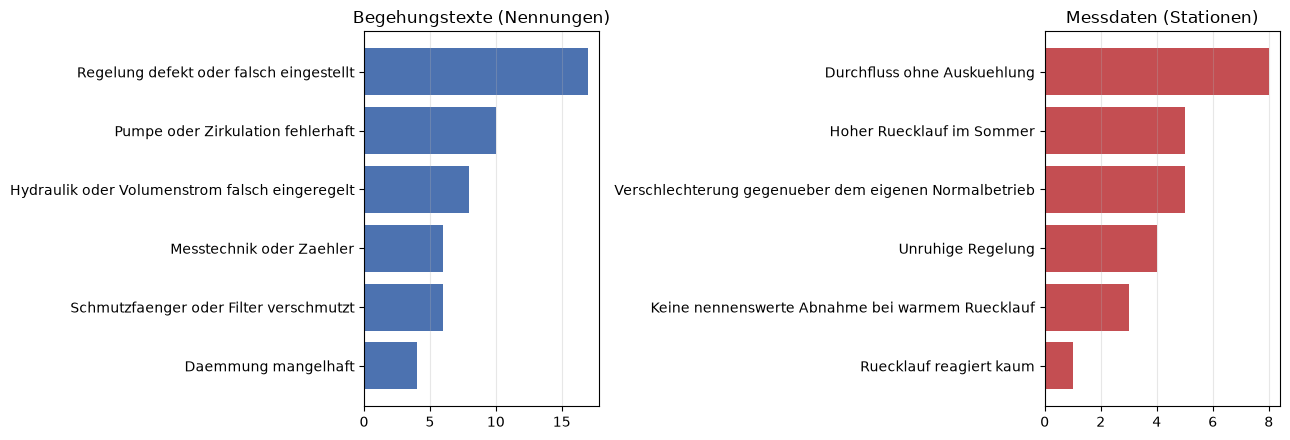

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
t = rang_text[rang_text["kategorie"] != ft.OHNE_BEFUND].head(6)
axes[0].barh(t["kategorie"][::-1], t["n_texte"][::-1], color="#4C72B0")
axes[0].set_title("Begehungstexte (Nennungen)")
m = rang_mess.head(6)
kurz = [s.split(",")[0] for s in m["muster"]]
axes[1].barh(kurz[::-1], m["n_stationen"][::-1], color="#C44E52")
axes[1].set_title("Messdaten (Stationen)")
for ax in axes:
    ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

- Messdaten: Kurzschlussverdacht 8 von 26, hoher Sommerrücklauf 5, Verschlechterung gegenüber dem Normalbetrieb 5, unruhige Regelung 4. In den Texten steht dagegen die Regelung vorn.

## 6 Erklärbares Baummodell

- Zweck ist Erklärung, nicht Vorhersage. Zielgröße: Rücklaufresiduum gegen die Netzerwartung, 54.201 Stationstage.
- Die Kreuzvalidierung hält ganze Stationen heraus.
- Die Spreizung (Vorlauf minus Rücklauf) bleibt draußen, weil sie rechnerisch am Rücklauf hängt. Zum Vergleich einmal mit Spreizung.

In [13]:
X, y, gruppen = em.baumdaten(panel)
print(f"Merkmalsmatrix {X.shape}, Zielgroesse {y.name}")
baum = em.fitte_baum(X, y, tiefe=3)
print(em.baumtext(baum, X.columns))

Merkmalsmatrix (54201, 10), Zielgroesse score_residuum_netz


+-- flow_median <= 173.2
|   +-- t_out_tag <= 15.2
|   |   +-- flow_median <= 91.2
|   |   |   +-- Ruecklaufresiduum: [-6.9]
|   |   +-- flow_median >  91.2
|   |   |   +-- Ruecklaufresiduum: [-1.1]
|   +-- t_out_tag >  15.2
|   |   +-- flow_median <= 15.8
|   |   |   +-- Ruecklaufresiduum: [-4.0]
|   |   +-- flow_median >  15.8
|   |   |   +-- Ruecklaufresiduum: [7.9]
+-- flow_median >  173.2
|   +-- power_mean <= 4.7
|   |   +-- last_anteil <= 0.5
|   |   |   +-- Ruecklaufresiduum: [28.7]
|   |   +-- last_anteil >  0.5
|   |   |   +-- Ruecklaufresiduum: [19.1]
|   +-- power_mean >  4.7
|   |   +-- power_mean <= 211.4
|   |   |   +-- Ruecklaufresiduum: [6.6]
|   |   +-- power_mean >  211.4
|   |   |   +-- Ruecklaufresiduum: [-10.8]



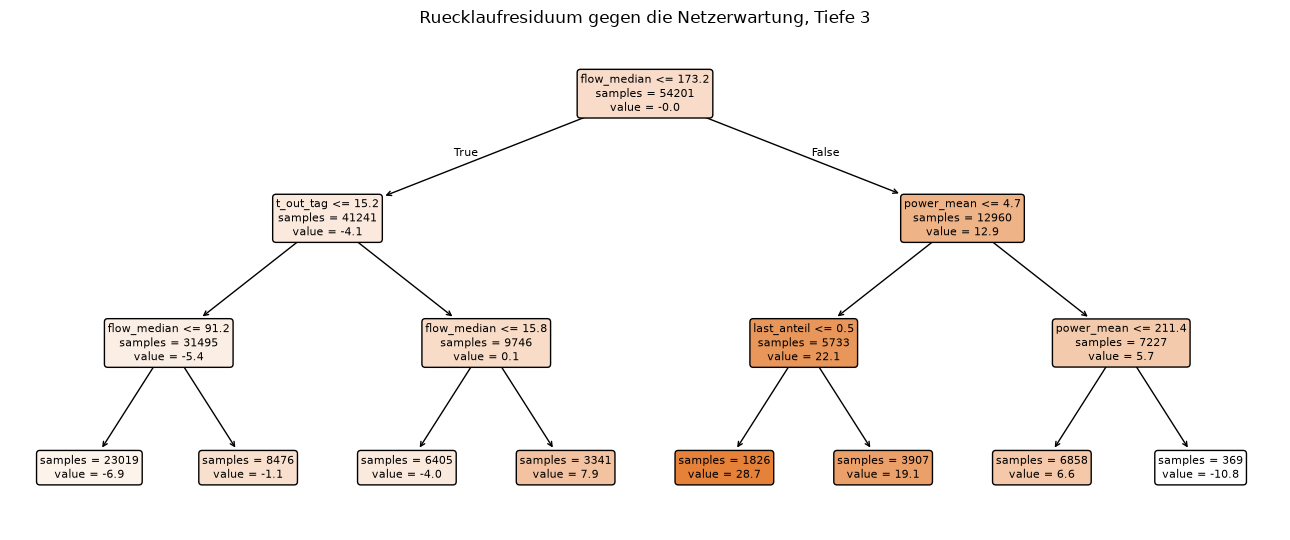

In [14]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(13, 5.5))
plot_tree(baum, feature_names=list(X.columns), filled=True, rounded=True,
          precision=1, fontsize=8, impurity=False, ax=ax)
ax.set_title("Ruecklaufresiduum gegen die Netzerwartung, Tiefe 3")
fig.tight_layout()
plt.show()

In [15]:
stab = em.baum_stabilitaet(X, y, gruppen, tiefe=3)
print("Kreuzvalidierung nach Stationen")
print(stab.round(3).to_string(index=False))
print(f"\nr2 ueber die Folds: {stab['r2_test'].mean():.3f} "
      f"plus minus {stab['r2_test'].std():.3f}")
print("Wurzelvariable je Fold:", ", ".join(sorted(set(stab["wurzel"]))))

Kreuzvalidierung nach Stationen
 fold  n_train  n_test  r2_test      wurzel  schwelle  wichtigste  anteil_wichtigste
    1    43433   10768    0.495 flow_median    176.75 flow_median              0.727
    2    43349   10852    0.421 flow_median    173.25 flow_median              0.714
    3    43432   10769    0.360 flow_median    186.25 flow_median              0.704
    4    43296   10905    0.351 flow_median    170.75 flow_median              0.771
    5    43294   10907    0.559 flow_median    202.25 flow_median              0.618

r2 ueber die Folds: 0.437 plus minus 0.089
Wurzelvariable je Fold: flow_median


In [16]:
Xs, ys, gs = em.baumdaten(panel, merkmale=em.BAUMMERKMALE_MIT_SPREIZUNG)
baum_s = em.fitte_baum(Xs, ys, tiefe=3)
stab_s = em.baum_stabilitaet(Xs, ys, gs, tiefe=3)
print("Vergleichsbaum mit Spreizung")
print(em.baumtext(baum_s, Xs.columns).split("\n")[0])
print(f"r2 ueber die Folds: {stab_s['r2_test'].mean():.3f}, "
      f"Wurzel: {', '.join(sorted(set(stab_s['wurzel'])))}")

Vergleichsbaum mit Spreizung
+-- dt_mean_loaded <= 22.1
r2 ueber die Folds: 0.618, Wurzel: dt_mean_loaded


- Wurzel in allen fünf Folds ist `flow_median` bei 170 bis 200 l/h. r² auf herausgehaltenen Stationen 0,44 ± 0,09.
- Wärmster Ast: Durchfluss über 173 l/h bei Leistung bis 4,7 kW, Residuum +28,7 K. Das passt zum Kurzschlussmuster.
- Mit Spreizung r² 0,62. Der Gewinn ist überwiegend rechnerisch.

## 7 Schweregrad

- Drei offengelegte Teile: Abweichung in Kelvin (Gewicht 0,45), Persistenz (0,35), Mehrdurchfluss (0,20).
- Stufen: hoch ab 55 Punkten, mittel ab 30.
- Mehrdurchfluss = Rücklaufabweichung geteilt durch die Spreizung. Anders als der Verbrauch je Heizgradstunde hängt er nicht von der Hausgröße ab.

In [17]:
grad = em.schweregrad(kenn, eff)
spalten = ["meter", "abweichung_k", "komp_abweichung", "persistenz",
           "komp_persistenz", "mehrdurchfluss", "komp_effizienz",
           "punkte", "stufe"]
print(grad.sort_values("punkte", ascending=False)[spalten]
      .head(12).round(3).to_string(index=False))
print()
print(treffer["stufe"].value_counts().to_string())

   meter  abweichung_k  komp_abweichung  persistenz  komp_persistenz  mehrdurchfluss  komp_effizienz  punkte stufe
72167782        27.185            1.000       0.770            1.000           3.077             1.0   100.0  hoch
68956351        21.725            1.000       0.766            1.000           4.109             1.0   100.0  hoch
80912182        28.007            1.000       0.969            1.000           3.451             1.0   100.0  hoch
72167793        24.496            1.000       0.890            1.000           3.032             1.0   100.0  hoch
72135480        24.636            1.000       0.733            1.000           4.927             1.0   100.0  hoch
81062289        18.051            1.000       0.385            0.770           1.347             1.0    91.9  hoch
68956360        12.512            0.834       0.480            0.961           0.790             1.0    91.2  hoch
72167777        12.244            0.816       0.367            0.734           1

- 15 Stationen hoch, 3 mittel, 8 niedrig. Die fünf mit 100 Punkten sind gedeckelt und untereinander nicht sortiert.
- Ein Fehler ohne Spur im Rücklauf bekommt keine Punkte.

## 8 Trefferliste, Export und Priorisierung

- Export nur mit Zählernummern. `em.exportiere` verweigert Spalten mit Bezug zu Adresse oder Namen.
- `src/priority.py` zeigt, wo eine Begehung überfällig ist. Die Trefferliste zeigt, wo der Betrieb heute auffällig ist.
- `pr.mit_empfehlung` stellt beides nebeneinander.

In [18]:
ziel = ROOT / "data" / "processed" / "empfehlungsliste.csv"
em.exportiere(treffer, str(ziel))
print(f"geschrieben: {ziel.relative_to(ROOT)}, {len(treffer)} Zeilen")
print("Spalten:", list(treffer.columns))

geschrieben: data/processed/empfehlungsliste.csv, 26 Zeilen
Spalten: ['meter', 'muster', 'stufe', 'punkte', 'massnahme', 'begruendung_kurz', 'evidenz', 'zweitmuster', 'abstand', 'persistenz', 'abweichung_k', 'mehrdurchfluss', 'verlust_kwh_je_kh', 'n_tage']


In [19]:
scores = pr.compute_scores()
kombiniert = pr.mit_empfehlung(scores, treffer)
vergleich = pr.rangvergleich(kombiniert)
print(f"Stationen in beiden Listen: {vergleich['n']:.0f}, "
      f"Spearman {vergleich['spearman']:.2f}")
zeig = kombiniert[kombiniert["muster"].notna()].head(10)
print(zeig[["Zählernummer", "prio_score", "anomalie_punkte",
            "schweregrad"]].to_string(index=False))

Stationen in beiden Listen: 25, Spearman 0.48
 Zählernummer  prio_score  anomalie_punkte schweregrad
     66761022       100.0             60.6        hoch
     80956410        94.5             50.5      mittel
     72135480        92.8            100.0        hoch
     72167793        92.3            100.0        hoch
     80912182        91.5            100.0        hoch
     72167782        91.5            100.0        hoch
     80912173        90.3             69.1        hoch
     68956360        90.3             91.2        hoch
     68956373        81.3             22.5     niedrig
     68956356        80.4             44.1      mittel


In [20]:
print("Beispiele fuer die Ausgabe an den Monteur")
for _, z in treffer.head(5).iterrows():
    print(f"\nZaehler {int(z['meter'])}  [{z['stufe']}, {z['punkte']:.0f} Punkte]")
    print(f"  Muster:    {z['muster']}")
    print(f"  Massnahme: {z['massnahme']}")
    print(f"  Warum:     {z['begruendung_kurz']}")

Beispiele fuer die Ausgabe an den Monteur

Zaehler 72167782  [hoch, 100 Punkte]
  Muster:    Durchfluss ohne Auskuehlung, Verdacht hydraulischer Kurzschluss
  Massnahme: Volumenstrom am Regelventil begrenzen, Bypass und Beimischung auf Kurzschluss pruefen, Schmutzfaenger kontrollieren
  Warum:     An 77 Prozent der ausgewerteten Tage auffaellig; Vorlauf und Ruecklauf liegen dicht beieinander, obwohl kaum Waerme abgenommen wird.

Zaehler 80912182  [hoch, 100 Punkte]
  Muster:    Durchfluss ohne Auskuehlung, Verdacht hydraulischer Kurzschluss
  Massnahme: Volumenstrom am Regelventil begrenzen, Bypass und Beimischung auf Kurzschluss pruefen, Schmutzfaenger kontrollieren
  Warum:     An 97 Prozent der ausgewerteten Tage auffaellig; Vorlauf und Ruecklauf liegen dicht beieinander, obwohl kaum Waerme abgenommen wird.

Zaehler 72167793  [hoch, 100 Punkte]
  Muster:    Durchfluss ohne Auskuehlung, Verdacht hydraulischer Kurzschluss
  Massnahme: Volumenstrom am Regelventil begrenzen, Bypass und 

- 26 Zeilen exportiert.
- 25 Stationen stehen in beiden Listen, Spearman 0,48: gleiche Richtung, aber kein Ersatz füreinander.

## 9 Nutzen für die ÜZ

- Wie viele Begehungen decken welchen Anteil der Punktsumme ab?
- Benennt die Liste Begehungen ohne Wirkung? Referenz ist der Wintervergleich aus Notebook 04 (`wintervergleich_kernwinter.csv`, 45 Begehungen).
- Die Liste nutzt auch die Zeit nach den Begehungen. Gemessen wird also Benennen, nicht Vorhersagen.

 5 Begehungen decken 33 Prozent der Punktsumme ab
10 Begehungen decken 60 Prozent der Punktsumme ab
15 Begehungen decken 82 Prozent der Punktsumme ab
20 Begehungen decken 95 Prozent der Punktsumme ab


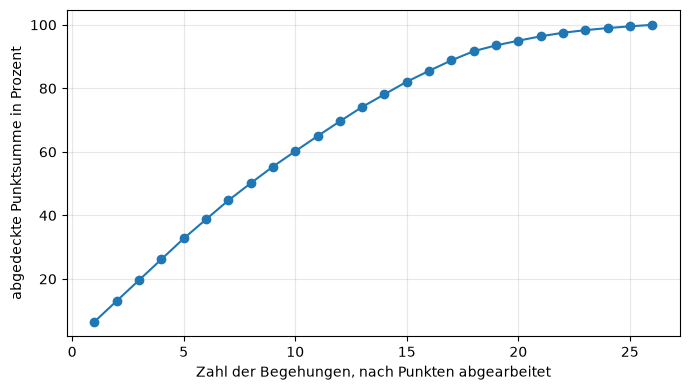

In [21]:
ab = em.abdeckung(treffer)
for n in (5, 10, 15, 20):
    if n <= len(ab):
        zeile = ab.iloc[n - 1]
        print(f"{n:2d} Begehungen decken {100 * zeile['anteil_punkte']:.0f} "
              f"Prozent der Punktsumme ab")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ab["n_begehungen"], 100 * ab["anteil_punkte"], marker="o")
ax.set_xlabel("Zahl der Begehungen, nach Punkten abgearbeitet")
ax.set_ylabel("abgedeckte Punktsumme in Prozent")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

In [22]:
winter = pd.read_csv(ROOT / "data" / "processed" /
                     "wintervergleich_kernwinter.csv")
nutzen = em.nutzenbilanz(treffer, winter)
print(nutzen["tafel"].to_string(index=False))
print(f"\nauswertbare Begehungen: {nutzen['n_begehungen']}")
print(f"ohne messbare Verbesserung: {nutzen['n_ohne_wirkung']} "
      f"({100 * nutzen['anteil_ohne_wirkung']:.0f} Prozent)")
print(f"davon in der Trefferliste: {nutzen['ohne_wirkung_erkannt']}")
print(f"Trefferquote bei schlechtem Zustand danach: "
      f"{100 * nutzen['trefferquote_schlecht']:.0f} Prozent")
print(f"Anteil der guten Faelle in der Liste: "
      f"{100 * nutzen['fehlalarm_gut']:.0f} Prozent")

zustand_vor zustand_nach  nicht_erkannt  in_trefferliste
        gut          gut             24                3
        gut     schlecht              1                3
   schlecht          gut              3                2
   schlecht     schlecht              5                4

auswertbare Begehungen: 45
ohne messbare Verbesserung: 9 (20 Prozent)
davon in der Trefferliste: 4
Trefferquote bei schlechtem Zustand danach: 54 Prozent
Anteil der guten Faelle in der Liste: 16 Prozent


- 10 Begehungen decken 60 % der Punktsumme ab, 20 Begehungen 95 %.
- 9 von 45 Begehungen ohne messbare Verbesserung, 4 davon in der Trefferliste.
- Bei schlechtem Zustand nach der Begehung stehen 54 % in der Liste, bei gutem Zustand 16 %.

## 10 Lauf-Kontext

- Schwellen, Gewichte und Kernergebnisse stehen in `data/processed/empfehlung_kontext.json`.

In [23]:
kontext = {
    "panel": {"zeilen": int(len(panel)),
              "stationen": int(panel["meter"].nunique()),
              "von": str(panel["datum"].min().date()),
              "bis": str(panel["datum"].max().date())},
    "kurzschlusscluster": int(KURZ),
    "tagesschwellen": {k: float(v) for k, v in schwellen.items()},
    "musterkatalog": [m["name"] for m in em.MUSTERKATALOG],
    "schwellen": {"min_evidenz": em.MIN_EVIDENZ,
                  "min_persistenz": em.MIN_PERSISTENZ,
                  "stufe_hoch": em.STUFE_HOCH,
                  "stufe_mittel": em.STUFE_MITTEL},
    "gewichte": {"abweichung": em.W_ABWEICHUNG,
                 "persistenz": em.W_PERSISTENZ,
                 "effizienz": em.W_EFFIZIENZ},
    "treffer": {"n": int(len(treffer)),
                "je_stufe": treffer["stufe"].value_counts().to_dict(),
                "ohne_muster": int((treffer["muster"] == em.OHNE_MUSTER).sum())},
    "freitexte": ft.kodierbilanz(kodiert).set_index("stufe")["n_texte"].to_dict(),
    "baum": {"r2_mittel": float(stab["r2_test"].mean()),
             "r2_streuung": float(stab["r2_test"].std()),
             "wurzeln": sorted(set(stab["wurzel"]))},
}
pfad = ROOT / "data" / "processed" / "empfehlung_kontext.json"
pfad.write_text(json.dumps(kontext, indent=2, ensure_ascii=False),
                encoding="utf-8")
print(json.dumps(kontext, indent=2, ensure_ascii=False))
tick("fertig")

{
  "panel": {
    "zeilen": 88792,
    "stationen": 93,
    "von": "2021-11-01",
    "bis": "2026-07-20"
  },
  "kurzschlusscluster": 1,
  "tagesschwellen": {
    "score_residuum_netz": 22.14267153112297,
    "score_residuum_station": 7.917458090679965
  },
  "musterkatalog": [
    "Durchfluss ohne Auskuehlung, Verdacht hydraulischer Kurzschluss",
    "Hoher Ruecklauf im Sommer, Verdacht Zirkulations- oder Speicherverlust",
    "Unruhige Regelung",
    "Ruecklauf reagiert kaum, Verdacht festsitzendes oder offenes Ventil",
    "Keine nennenswerte Abnahme bei warmem Ruecklauf",
    "Ruecklauf dauerhaft ueber der Netzerwartung",
    "Verschlechterung gegenueber dem eigenen Normalbetrieb"
  ],
  "schwellen": {
    "min_evidenz": 0.6,
    "min_persistenz": 0.1,
    "stufe_hoch": 55.0,
    "stufe_mittel": 30.0
  },
  "gewichte": {
    "abweichung": 0.45,
    "persistenz": 0.35,
    "effizienz": 0.2
  },
  "treffer": {
    "n": 26,
    "je_stufe": {
      "hoch": 15,
      "niedrig": 8,
    

## Zusammenfassung & Bewertung

**Ergebnis**
- Alle 26 auffälligen Stationen haben jetzt ein Muster. Mit der alten Zuordnung blieben 19 ohne verwertbare Diagnose.
- 15 Stationen haben einen hohen Schweregrad.

**Belastbar**
- Die große Restkategorie war ein Konstruktionsfehler der alten Regeln, keine Eigenschaft der Daten.
- Der Kurzschlussverdacht ist physikalisch stimmig. Der Baum findet dieselbe Konstellation stabil als wärmsten Ast.
- Nach der Begehung trennt die Liste schlechte von guten Fällen (54 % gegen 16 % in der Liste).

**Schwach**
- Text- und Messrangliste laufen auseinander. Ein Teil der Protokolle beschreibt nur das Gebäude.
- 68956351 wird als Kurzschluss statt als Ventil eingeordnet.
- Der Schweregrad sieht nur auf den Rücklauf. Fünf Zähler haben ein Jahr mehr Beobachtungszeit.

**Offen**
- Die Zuordnung Muster zu Maßnahme ist physikalisch begründet, bleibt aber ein Vorschlag für die ÜZ.
- Mindestevidenz, Persistenzschwelle, Stufen und Gewichte sind gesetzt, nicht kalibriert.
- Wie lassen sich offenes Ventil und Kurzschluss im Messbild trennen?